In [184]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from surprise import Dataset, Reader, SVD, accuracy
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

In [185]:
ratings = pd.read_csv('data_hw/ratings.csv')
books = pd.read_csv('data_hw/books.csv')
tags = pd.read_csv('data_hw/tags.csv')
book_tags = pd.read_csv('data_hw/book_tags.csv')

In [186]:
# Этап 1: знакомство с данными и EDA (Exploratory Data Analysis)
# Распределение оценок. Есть ли смещение в сторону высоких оценок?

In [187]:
ratings.head()

,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


In [188]:
ratings.shape

(981756, 3)

In [189]:
rating_counts = ratings['rating'].value_counts().sort_index()
rating_counts

rating
1     19575
2     63231
3    248623
4    357366
5    292961
Name: count, dtype: int64

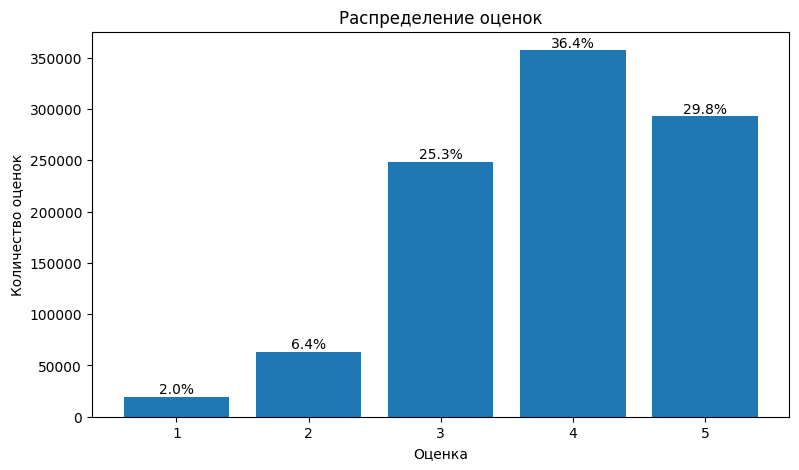

In [190]:
plt.figure(figsize=(9, 5))
bars = plt.bar(rating_counts.index, rating_counts.values)

plt.title('Распределение оценок')
plt.xlabel('Оценка')
plt.ylabel('Количество оценок')
plt.xticks([1,2,3,4,5])

for bar, count in zip(bars, rating_counts.values):
    percent = count / len(ratings) * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{percent:.1f}%',
        ha='center',
        va='bottom'
    )

plt.show()

Распределение оценок заметно смещено в сторону высоких значений: 66,2% оценок составляют 4 и 5, тогда как на оценки 1 и 2 приходится лишь 8,4%.

Это свидетельствует о смещении в сторону положительных оценок. Возможная причина — пользователи чаще читают и оценивают книги, которые изначально соответствуют их интересам.

Такое смещение может затруднять обучение рекомендательных моделей, поскольку положительные оценки преобладают и моделям сложнее различать предпочтения пользователей.

In [191]:
# Анализ активности пользователей. Постройте график «Взаимоотношение количества пользователей и количества оценок». Выявите активных пользователей и пользователей с малым количеством взаимодействий (проблема холодного старта).

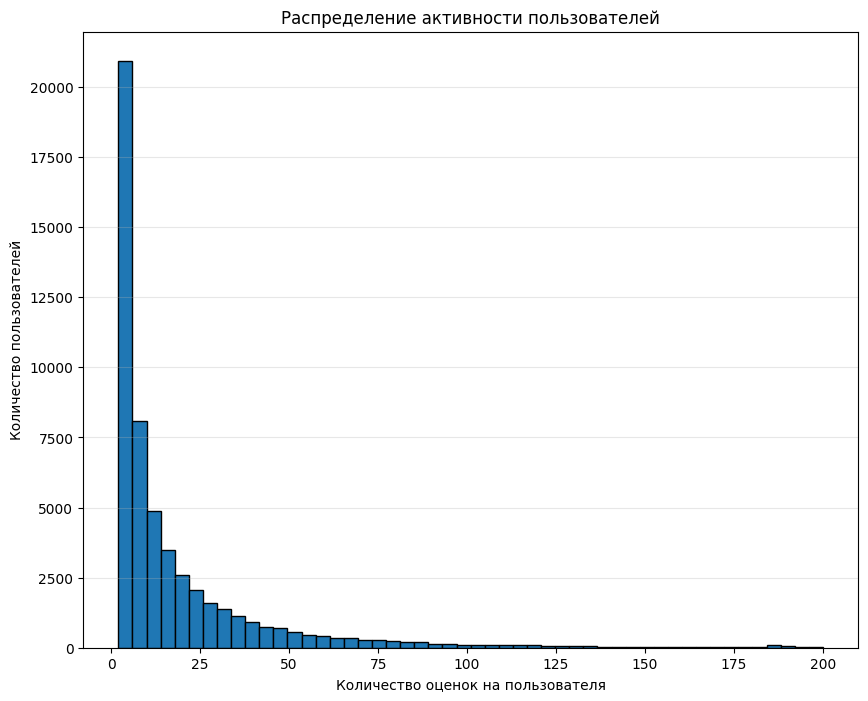

In [192]:
ratings_per_user = ratings.groupby('user_id').size()

plt.figure(figsize=(10, 8))
plt.hist(ratings_per_user, bins=50, edgecolor='black')

plt.title('Распределение активности пользователей')
plt.xlabel('Количество оценок на пользователя')
plt.ylabel('Количество пользователей')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [193]:
users_count = ratings['user_id'].nunique()
print(f'Количество пользователей: {users_count}')

ratings_count = ratings.shape[0]
print(f'Количество оценок: {ratings_count}')

print(f'Максимум оценок: {ratings_per_user.max()}')
print(f'Минимум оценок: {ratings_per_user.min()}')

print(f'Среднее число оценок: {ratings_per_user.mean():.2f}')
print(f'Медианное число оценок: {ratings_per_user.median():.0f}')

Количество пользователей: 53424
Количество оценок: 981756
Максимум оценок: 200
Минимум оценок: 2
Среднее число оценок: 18.38
Медианное число оценок: 8


In [242]:
ACTIVE_COUNT = 25

active_users = (ratings_per_user >= ACTIVE_COUNT).sum()

print(f'Активных пользователей ({ACTIVE_COUNT} оценок): {active_users} ({active_users / len(ratings_per_user):.1%})')

Активных пользователей (25 оценок): 11880 (22.2%)


Распределение активности пользователей имеет выраженную правостороннюю асимметрию: большинство пользователей оставили небольшое количество оценок, тогда как относительно небольшая группа активных пользователей оценила десятки и даже сотни книг.

Это указывает на проблему холодного старта для пользователей с малым количеством взаимодействий. Моделям коллаборативной фильтрации будет сложно формировать для них качественные персонализированные рекомендации из-за недостатка информации об их предпочтениях.

In [195]:
# Анализ популярности книг. Постройте график «Количество книг vs количество оценок». Выявите популярные книги и «длинный хвост».

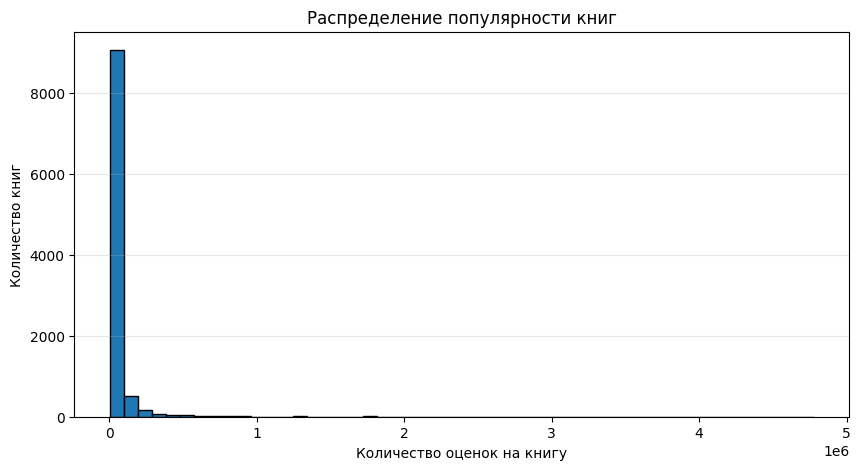

In [196]:
ratings_per_book = books.set_index('book_id')['ratings_count']

plt.figure(figsize=(10, 5))
plt.hist(ratings_per_book, bins=50, edgecolor='black')

plt.title('Распределение популярности книг')
plt.xlabel('Количество оценок на книгу')
plt.ylabel('Количество книг')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [197]:
print(f'Всего оценённых книг: {len(ratings_per_book)}')
print(f'Минимум оценок: {ratings_per_book.min()}')
print(f'Максимум оценок: {ratings_per_book.max()}')
print(f'Среднее число оценок: {ratings_per_book.mean():.2f}')
print(f'Медианное число оценок: {ratings_per_book.median():.0f}')

Всего оценённых книг: 10000
Минимум оценок: 2716
Максимум оценок: 4780653
Среднее число оценок: 54001.24
Медианное число оценок: 21156


In [198]:
top_books = (
    ratings_per_book
    .rename('ratings_count')
    .reset_index()
    .merge(books[['book_id', 'title', 'authors']], on='book_id')
    .sort_values('ratings_count', ascending=False)
    .head(10)
)

print(top_books.to_string(index=False))

 book_id  ratings_count                                                    title                     authors
 2767052        4780653                  The Hunger Games (The Hunger Games, #1)             Suzanne Collins
       3        4602479 Harry Potter and the Sorcerer's Stone (Harry Potter, #1) J.K. Rowling, Mary GrandPré
   41865        3866839                                  Twilight (Twilight, #1)             Stephenie Meyer
    2657        3198671                                    To Kill a Mockingbird                  Harper Lee
    4671        2683664                                         The Great Gatsby         F. Scott Fitzgerald
11870085        2346404                                   The Fault in Our Stars                  John Green
    5907        2071616                                               The Hobbit              J.R.R. Tolkien
    5107        2044241                                   The Catcher in the Rye               J.D. Salinger
    1885        203

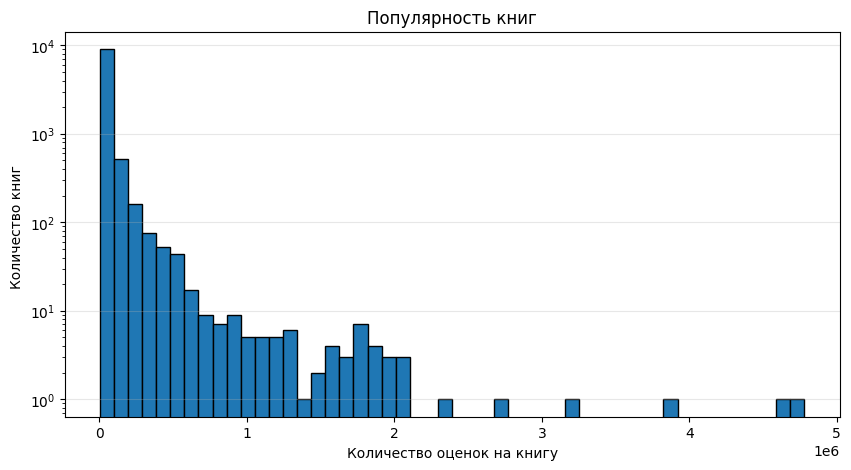

In [199]:
plt.figure(figsize=(10, 5))
plt.hist(ratings_per_book, bins=50, edgecolor='black')
plt.yscale('log')

plt.title('Популярность книг')
plt.xlabel('Количество оценок на книгу')
plt.ylabel('Количество книг ')
plt.grid(axis='y', alpha=0.3)

plt.show()

Анализ распределения количества оценок по книгам выявил выраженную правостороннюю асимметрию. Большинство книг имеет относительно небольшое количество оценок, тогда как отдельные популярные произведения получили миллионы оценок.

Среднее количество оценок составляет 54 001, что значительно превышает медианное значение 21 156. Максимальное количество оценок достигает 4 780 653 (*The Hunger Games*).

На графиках наблюдается характерный эффект «длинного хвоста»: большое количество менее популярных книг сосредоточено в левой части распределения, а небольшое число наиболее популярных книг формирует протяжённый правый хвост.

Такое распределение указывает на неравномерность популярности книг и потенциальную проблему: рекомендательные системы могут отдавать предпочтение наиболее популярным произведениям, недостаточно учитывая менее известные книги.

Для уменьшения данного смещения можно использовать персонализированные модели, учитывающие индивидуальные предпочтения пользователей, и механизмы повышения разнообразия рекомендаций.

In [200]:
# Визуализируйте самые частые теги для книг (на основе book_tags.csv).

In [201]:
tags_counts = (book_tags.groupby('tag_id')['goodreads_book_id']
               .nunique()
               .reset_index(name='books_count')
               .sort_values('books_count', ascending=False))
tags_counts = tags_counts.merge(tags, on='tag_id')
tags_counts.head(10)

,tag_id,books_count,tag_name
0,30574,9983,to-read
1,11557,9881,favorites
2,22743,9857,owned
3,5207,9799,books-i-own
4,8717,9776,currently-reading
5,18045,9415,library
6,22753,9221,owned-books
7,11743,9097,fiction
8,30521,8692,to-buy
9,17213,8316,kindle


In [202]:
top_tags = tags_counts.nlargest(20, 'books_count')

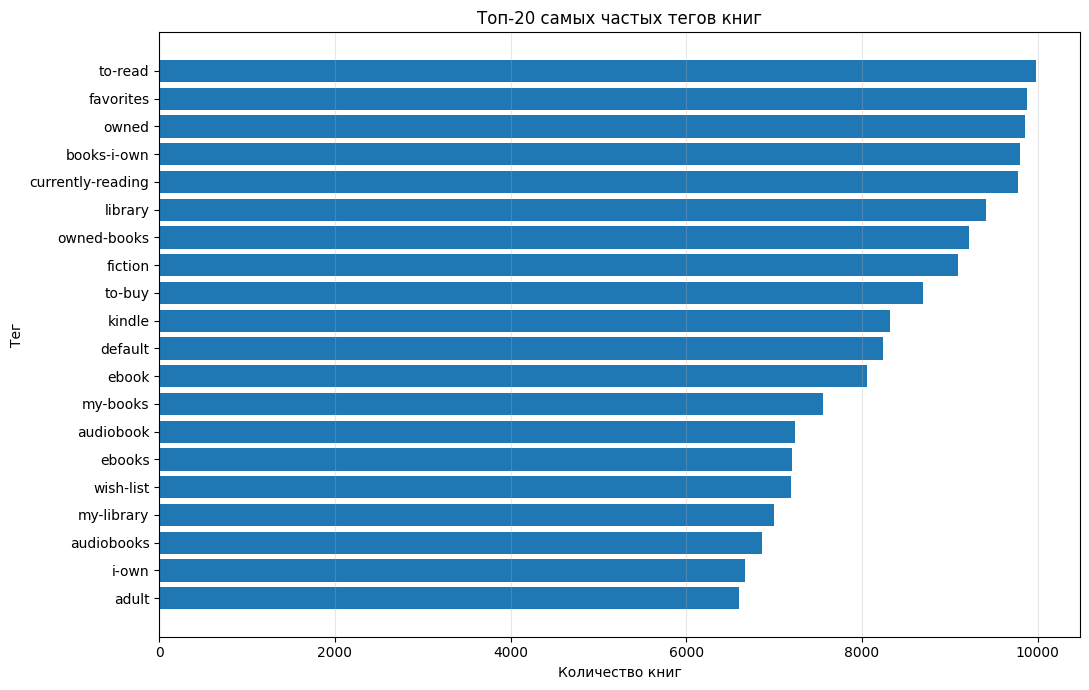

In [203]:
plt.figure(figsize=(11, 7))
plt.barh(top_tags['tag_name'], top_tags['books_count'])

plt.title('Топ-20 самых частых тегов книг')
plt.xlabel('Количество книг')
plt.ylabel('Тег')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

Анализ топ-20 наиболее распространённых тегов показал, что большинство из них связано с пользовательскими действиями и способом хранения или чтения книг, а не с литературными жанрами.

Наиболее частые теги — `to-read`, `favorites`, `owned`, `books-i-own` и `currently-reading` — встречаются практически у всех книг. Среди содержательных характеристик выделяется тег `fiction`.

Это показывает, что исходные теги содержат значительное количество малоинформативных признаков для определения тематической близости книг.

При разработке Content-Based рекомендательной системы целесообразно отфильтровать служебные теги и использовать TF-IDF для уменьшения влияния слишком распространённых признаков.

In [204]:
# Какие основные проблемы данных (разреженность, смещение популярности) видны уже на этапе EDA?

In [205]:
n_users = ratings['user_id'].nunique()
n_books = books['book_id'].nunique()

n_interactions = ratings[['user_id', 'book_id']].drop_duplicates().shape[0]

sparsity = 1 - n_interactions / (n_users * n_books)

print(f'Пользователей: {n_users}')
print(f'Книг: {n_books}')
print(f'Взаимодействий: {n_interactions}')
print(f'Разреженность: {sparsity:.2%}')

Пользователей: 53424
Книг: 10000
Взаимодействий: 979478
Разреженность: 99.82%


**1. Разреженность данных.** Матрица взаимодействий пользователей и книг преимущественно пустая, поскольку каждый пользователь оценил лишь небольшую часть каталога. Это затрудняет применение коллаборативной фильтрации и выявление сходства между книгами.

**2. Смещение популярности.** Распределение популярности книг имеет выраженный длинный хвост: большинство книг обладает относительно небольшим количеством оценок, тогда как отдельные произведения получили миллионы оценок. Это создаёт риск того, что рекомендательные модели будут отдавать предпочтение популярным книгам в ущерб менее известным.

**3. Холодный старт.** Значительная часть пользователей имеет небольшое количество взаимодействий. Для таких пользователей сложно формировать персонализированные рекомендации из-за недостатка информации об их предпочтениях.

**4. Смещение оценок.** Оценки 4 и 5 составляют 66,2% всех взаимодействий, что указывает на преобладание положительных оценок. Такое распределение может затруднять обучение моделей и точное различение пользовательских предпочтений.

**Вывод:** для построения качественной рекомендательной системы необходимо учитывать разреженность данных, неравномерную популярность книг и недостаток информации о новых пользователях. Для решения этих проблем целесообразно сравнить несколько подходов: Popularity-based, Content-Based, Item-Based Collaborative Filtering и SVD.

In [206]:
# Этап 2: базовые и контентные модели
# Неперсонализированная модель

In [207]:
N = 10
min_ratings = 50

# Рассчитываем среднюю оценку и число оценок каждой книги
book_stats = ratings.groupby('book_id')['rating'].agg(mean_rating='mean', ratings_count='count').reset_index()

# Оставляем книги с достаточным количеством оценок
book_stats = book_stats[book_stats['ratings_count'] >= min_ratings]

# Добавляем названия и авторов
book_stats = book_stats.merge(books[['id', 'title', 'authors']], left_on='book_id', right_on='id')

# Сортируем по среднему рейтингу и количеству оценок
top_books = (book_stats.sort_values(['mean_rating', 'ratings_count'], ascending=[False, False]).head(N))

top_books[['book_id', 'title', 'authors', 'mean_rating', 'ratings_count']].reset_index(drop=True)

,book_id,title,authors,mean_rating,ratings_count
0,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",4.820225,89
1,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,4.780000,100
2,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.780000,100
3,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,4.777778,99
4,8946,The Divan,Hafez,4.774194,93
5,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré",4.770000,100
6,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,4.770000,100
7,4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,4.750000,100
8,5580,The Calvin and Hobbes Lazy Sunday Book,Bill Watterson,4.750000,100
9,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson,4.750000,100


**Неперсонализированная модель (Popularity-Based)**

Реализована базовая рекомендательная модель, формирующая Top-10 книг на основе среднего пользовательского рейтинга с минимальным порогом в 50 оценок.

Наибольшую среднюю оценку получила книга *ESV Study Bible* (4.82 на основе 89 оценок).

Модель не требует информации о конкретном пользователе и может использоваться для рекомендаций новым пользователям.

Главный недостаток — отсутствие персонализации: все пользователи получают одинаковые рекомендации независимо от индивидуальных предпочтений.

Дополнительно результаты ограничены особенностями `ratings.csv`, где представлено не более 100 оценок на книгу.

In [208]:
# Контентная модель
# Объедините данные о книгах с их тегами. Для каждой книги создайте текстовый «профиль» из названия (original_title) и списка тегов.

In [209]:
book_tag_names = book_tags.merge(tags[['tag_id', 'tag_name']], on='tag_id')
book_tag_names.head()

,goodreads_book_id,tag_id,count,tag_name
0,1,30574,167697,to-read
1,2,30574,24549,to-read
2,3,30574,496107,to-read
3,5,30574,11909,to-read
4,6,30574,298,to-read


In [210]:
# Заменяем пробелы и дефисы на подчёркивания, чтобы составные теги воспринимались как одно слово
book_tag_names['tag_name'] = (book_tag_names['tag_name'].fillna('').str.replace(r'\W+', '_', regex=True))

# Собираем теги каждой книги в одну строку
tags_by_book = (book_tag_names.groupby('goodreads_book_id')['tag_name'].agg(' '.join).rename('tags_text'))

# Добавляем теги к книгам
book_profiles = books.merge(tags_by_book, left_on='book_id', right_index=True, how='left')

# Создаём текстовый профиль из названия и тегов
book_profiles['profile'] = (
    book_profiles['original_title'].fillna(book_profiles['title']).fillna('')
    + ' ' + book_profiles['tags_text'].fillna('')
)


book_profiles = book_profiles.reset_index(drop=True)
book_profiles.head(10)

,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url,tags_text,profile
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...,to_read fantasy favorites currently_reading yo...,The Hunger Games to_read fantasy favorites cur...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...,to_read fantasy favorites currently_reading yo...,Harry Potter and the Philosopher's Stone to_re...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...,to_read fantasy favorites currently_reading yo...,Twilight to_read fantasy favorites currently_r...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...,to_read favorites currently_reading young_adul...,To Kill a Mockingbird to_read favorites curren...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...,to_read favorites currently_reading young_adul...,The Great Gatsby to_read favorites currently_r...
5,6,11870085,11870085,16827462,226,525478817,9.780525e+12,John Green,2012.0,The Fault in Our Stars,...,140739,47994,92723,327550,698471,1311871,https://images.gr-assets.com/books/1360206420m...,https://images.gr-assets.com/books/1360206420s...,to_read favorites currently_reading young_adul...,The Fault in Our Stars to_read favorites curre...
6,7,5907,5907,1540236,969,618260307,9.780618e+12,J.R.R. Tolkien,1937.0,The Hobbit or There and Back Again,...,37653,46023,76784,288649,665635,1119718,https://images.gr-assets.com/books/1372847500m...,https://images.gr-assets.com/books/1372847500s...,to_read fantasy favorites currently_reading yo...,The Hobbit or There and Back Again to_read fan...
7,8,5107,5107,3036731,360,316769177,9.780317e+12,J.D. Salinger,1951.0,The Catcher in the Rye,...,44920,109383,185520,455042,661516,709176,https://images.gr-assets.com/books/1398034300m...,https://images.gr-assets.com/books/1398034300s...,to_read favorites currently_reading young_adul...,The Catcher in the Rye to_read favorites curre...
8,9,960,960,3338963,311,1416524797,9.781417e+12,Dan Brown,2000.0,Angels & Demons,...,25112,77841,145740,458429,716569,680175,https://images.gr-assets.com/books/1303390735m...,https://images.gr-assets.com/books/1303390735s...,to_read fantasy favorites currently_reading fi...,Angels & Demons to_read fantasy favorites cur...
9,10,1885,1885,3060926,3455,679783261,9.780680e+12,Jane Austen,1813.0,Pride and Prejudice,...,49152,54700,86485,284852,609755,1155673,https://images.gr-assets.com/books/1320399351m...,https://images.gr-assets.com/books/1320399351s...,to_read favorites young_adult fiction books_i_...,Pride and Prejudice to_read favorites young_ad...


In [211]:
# Векторизуйте эти профили с помощью TF-IDF.

In [212]:
book_indices = pd.Series(book_profiles.index, index=book_profiles['id'])

vectorizer = TfidfVectorizer(stop_words='english', max_df=0.9)
tfidf_matrix = vectorizer.fit_transform(book_profiles['profile'])
print(f'Размер TF-IDF-матрицы: {tfidf_matrix.shape}')

Размер TF-IDF-матрицы: (10000, 40347)


In [213]:
def get_similar_books(book_id, N=5):
    if book_id not in book_indices.index:
        raise ValueError(f'Книга {book_id} не найдена')

    if not 1 <= N < len(book_profiles):
        raise ValueError(f'N должно быть от 1 до {len(book_profiles) - 1}')

    idx = book_indices.loc[book_id]

    # Косинусное сходство выбранной книги со всеми остальными
    similarities = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).flatten()

    # Исключаем исходную книгу
    similarities[idx] = -1

    # Индексы N наиболее похожих книг
    top_indices = similarities.argsort()[-N:][::-1]

    # Формируем результат
    result = book_profiles.iloc[top_indices][['id', 'title', 'authors']].copy()
    result['similarity'] = similarities[top_indices]

    return result.reset_index(drop=True)

In [214]:
# Проверям работу функции
book_id = 1

print('Исходная книга:')
print(book_profiles.loc[book_profiles['id'] == book_id, 'title'].iloc[0])

print('\nПохожие книги:')
display(get_similar_books(book_id, N=5))

Исходная книга:
The Hunger Games (The Hunger Games, #1)

Похожие книги:


,id,title,authors,similarity
0,17,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,0.823092
1,20,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,0.771573
2,507,The Hunger Games Trilogy Boxset (The Hunger Ga...,Suzanne Collins,0.746859
3,12,"Divergent (Divergent, #1)",Veronica Roth,0.578766
4,69,"Insurgent (Divergent, #2)",Veronica Roth,0.512619


**Контентная рекомендательная модель (Content-Based)**

Реализована контентная рекомендательная модель на основе TF-IDF-векторизации названий и тегов книг. Для определения сходства используется косинусная мера близости.

При тестировании на книге *The Hunger Games* модель рекомендовала продолжения серии (*Catching Fire*, *Mockingjay*), а также тематически близкие произведения (*Divergent*, *Insurgent*).

Значения косинусного сходства составили от 0,513 до 0,823, что подтверждает способность модели находить книги с близкими текстовыми характеристиками.

**Преимущества:** модель не требует истории оценок пользователей и позволяет находить тематически похожие книги.

**Недостатки:** качество зависит от информативности тегов и названий. Также модель склонна рекомендовать книги одной серии, что может снижать разнообразие рекомендаций.

In [215]:
# Этап 3: коллаборативная фильтрация (Collaborative Filtering — CF)
# Постройте матрицу взаимодействий «пользователь — книга»

In [216]:
duplicates = ratings.duplicated(subset=['user_id', 'book_id'])

print(f'Всего оценок: {len(ratings)}')
print(f'Повторных оценок одной книги одним пользователем: {duplicates.sum()}')
print(f'Уникальных пар пользователь-книга: {len(ratings) - duplicates.sum()}')

Всего оценок: 981756
Повторных оценок одной книги одним пользователем: 2278
Уникальных пар пользователь-книга: 979478


In [217]:
ratings_unique = ratings.groupby(['user_id', 'book_id'], as_index=False)['rating'].mean()

# Получаем уникальные идентификаторы пользователей и книг
user_ids = np.sort(ratings_unique['user_id'].unique())
book_ids = np.sort(books['id'].unique())

# Сопоставляем идентификаторы с индексами матрицы
user_indices = pd.Index(user_ids).get_indexer(ratings_unique['user_id'])
book_indices_cf = pd.Index(book_ids).get_indexer(ratings_unique['book_id'])

# Создаём разреженную матрицу взаимодействий
user_item_matrix = csr_matrix(
    (ratings_unique['rating'].to_numpy(), (user_indices, book_indices_cf)),
    shape=(len(user_ids), len(book_ids)),
    dtype=np.float32
)

print(f'Размер матрицы: {user_item_matrix.shape}')
print(f'Количество взаимодействий: {user_item_matrix.nnz}')
print(f'Разреженность: {1 - user_item_matrix.nnz / np.prod(user_item_matrix.shape):.2%}')


Размер матрицы: (53424, 10000)
Количество взаимодействий: 979478
Разреженность: 99.82%


In [218]:
# Транспонируем матрицу: теперь строки — книги, столбцы — пользователи
item_user_matrix = user_item_matrix.T.tocsr()

# Рассчитываем попарное косинусное сходство книг
item_similarity = cosine_similarity(item_user_matrix, dense_output=False)

# Исключаем сходство книги с самой собой
item_similarity.setdiag(0)
item_similarity.eliminate_zeros()

print(f'Размер матрицы сходства: {item_similarity.shape}')
print(f'Количество ненулевых значений: {item_similarity.nnz}')

Размер матрицы сходства: (10000, 10000)
Количество ненулевых значений: 24367518


In [219]:
# словари для преобразования реальных идентификаторов пользователей и книг в индексы матриц.
user_id_to_idx = {user_id: idx for idx, user_id in enumerate(user_ids)}
book_id_to_idx = {book_id: idx for idx, book_id in enumerate(book_ids)}

In [220]:
def predict_rating(user_id, book_id, K=5):
    if user_id not in user_id_to_idx:
        raise ValueError(f'Пользователь {user_id} не найден')

    if book_id not in book_id_to_idx:
        raise ValueError(f'Книга {book_id} не найдена')

    if K < 1:
        raise ValueError('K должно быть положительным')

    user_idx = user_id_to_idx[user_id]
    book_idx = book_id_to_idx[book_id]

    # Получаем книги, оценённые пользователем
    user_ratings = user_item_matrix[user_idx]
    rated_indices = user_ratings.indices
    rated_values = user_ratings.data

    # Исключаем целевую книгу, если пользователь её уже оценил
    mask = rated_indices != book_idx
    rated_indices = rated_indices[mask]
    rated_values = rated_values[mask]

    # Сходство целевой книги с оценёнными пользователем книгами
    similarities = item_similarity[book_idx, rated_indices].toarray().ravel()

    # Оставляем только книги с положительным сходством
    mask = similarities > 0
    similarities = similarities[mask]
    rated_values = rated_values[mask]

    if len(similarities) == 0:
        return np.nan

    # Выбираем K наиболее похожих книг
    top_indices = np.argsort(similarities)[-K:]
    top_similarities = similarities[top_indices]
    top_ratings = rated_values[top_indices]

    # Вычисляем взвешенную среднюю оценку
    prediction = np.dot(top_similarities, top_ratings) / top_similarities.sum()

    return float(prediction)

In [221]:
# Находим наиболее активного пользователя
active_user_idx = np.argmax(user_item_matrix.getnnz(axis=1))
user_id = user_ids[active_user_idx]

print(f'Самый активный пользователь: {user_id}')
print(f'Количество оценок: {user_item_matrix[active_user_idx].nnz}')

# Проверяем предсказание для The Hunger Games
prediction = predict_rating(user_id, 1, K=5)

print(f'Предсказанная оценка The Hunger Games: {prediction:.2f}')

Самый активный пользователь: 12874
Количество оценок: 200
Предсказанная оценка The Hunger Games: 4.19


In [222]:
# Проверим, сколько соседей использовала модель
user_idx = user_id_to_idx[user_id]
book_idx = book_id_to_idx[book_id]

user_ratings = user_item_matrix[user_idx]
rated_indices = user_ratings.indices
rated_values = user_ratings.data

mask = rated_indices != book_idx
rated_indices = rated_indices[mask]
rated_values = rated_values[mask]

similarities = item_similarity[book_idx, rated_indices].toarray().ravel()

neighbors = pd.DataFrame({
    'book_id': book_ids[rated_indices],
    'rating': rated_values,
    'similarity': similarities
})

neighbors = neighbors[neighbors['similarity'] > 0].nlargest(5, 'similarity')
neighbors = neighbors.merge(books[['id', 'title']], left_on='book_id', right_on='id')

print(f'Найдено соседей: {len(neighbors)}')
display(neighbors[['title', 'rating', 'similarity']])

Найдено соседей: 5


,title,rating,similarity
0,Harry Potter and the Sorcerer's Stone (Harry P...,4.0,0.555526
1,The Secret Garden,4.0,0.488009
2,The Great Gatsby,4.0,0.480233
3,"Angels & Demons (Robert Langdon, #1)",5.0,0.472808
4,"The Lion, the Witch, and the Wardrobe (Chronic...",4.0,0.472192


**Результаты Item-Based Collaborative Filtering**

Реализован алгоритм Item-Based Collaborative Filtering с использованием косинусного сходства между векторами пользовательских оценок книг. Предсказание оценки формируется как взвешенное среднее оценок K наиболее похожих книг, ранее оценённых пользователем.

Для пользователя с 200 оценёнными книгами найдены все 5 соседей с коэффициентами сходства от 0,472 до 0,556. Предсказанная оценка составила 4,19.

Эксперимент демонстрирует влияние разреженности данных на коллаборативную фильтрацию. Для пользователей с небольшим количеством взаимодействий алгоритму сложнее найти достаточное число похожих книг, что ограничивает надёжность прогнозов.

Для повышения устойчивости модели можно использовать минимальный порог сходства и резервную стратегию рекомендаций при недостатке соседей.

In [223]:
# В чём вычислительная сложность этого подхода? Как его можно оптимизировать для больших данных?

Основная вычислительная сложность Item-Based Collaborative Filtering связана с расчётом матрицы попарного сходства книг. Для плотных матриц временная сложность составляет \(O(I^2U)\), где \(I\) — количество книг, \(U\) — количество пользователей. Хранение полной матрицы сходства требует \(O(I^2)\) памяти.

Для оптимизации используются разреженные матрицы (CSR), позволяющие хранить только существующие оценки и эффективнее выполнять вычисления. Дополнительно можно сохранять только Top-K ближайших соседей для каждой книги, вычислять сходство по запросу и применять алгоритмы приближённого поиска ближайших соседей (ANN).

В реализованной модели уже используются разреженные матрицы, что позволяет сократить потребление памяти. Однако при значительном увеличении количества книг полный расчёт попарных сходств станет вычислительно затратным. Поэтому для масштабирования целесообразно ограничивать количество сохраняемых соседей и избегать построения полной матрицы сходства.

In [224]:
# Этап 4: матричные разложения (Matrix Factorization)

In [225]:
train_ratings, test_ratings = train_test_split(ratings_unique, test_size=0.2, random_state=42)

reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(train_ratings[['user_id', 'book_id', 'rating']], reader)
trainset = data.build_full_trainset()

print(f'Обучающих оценок: {len(train_ratings)}')
print(f'Тестовых оценок: {len(test_ratings)}')

Обучающих оценок: 783582
Тестовых оценок: 195896


In [226]:
# Обучение SVD
svd_model = SVD(n_factors=50, n_epochs=20, random_state=42)
svd_model.fit(trainset)

print('SVD обучена')

SVD обучена


In [227]:
prediction = svd_model.predict(user_id, book_id)

print(f'Пользователь: {user_id}')
print(f'Книга: {books.loc[books["id"] == book_id, "title"].iloc[0]}')
print(f'Предсказанная оценка SVD: {prediction.est:.2f}')

Пользователь: 12874
Книга: The Hunger Games (The Hunger Games, #1)
Предсказанная оценка SVD: 3.97


Реализована модель матричной факторизации SVD с использованием библиотеки Surprise. Модель обучена на 80% пользовательских оценок с 50 скрытыми факторами и 20 эпохами обучения.

Для того же пользователя предсказанная оценка составила 3,97, ранее реализованная Item-Based CF предсказала 4,19.

Различия объясняются использованием разных алгоритмов. Для объективного сравнения качества моделей необходимо оценить их на общей тестовой выборке.

In [228]:
testset = list(test_ratings[['user_id', 'book_id', 'rating']].itertuples(index=False, name=None))

# Предсказываем оценки на тестовой выборке
predictions = svd_model.test(testset)

# Вычисляем RMSE
rmse = accuracy.rmse(predictions)

print(f'RMSE на тестовой выборке: {rmse:.4f}')

RMSE: 0.8403
RMSE на тестовой выборке: 0.8403


**Оценка качества модели SVD**

Данные были разделены на обучающую (80%) и тестовую (20%) выборки. Модель SVD обучена с использованием библиотеки Surprise с 50 скрытыми факторами и 20 эпохами обучения.

На тестовой выборке получено значение **RMSE = 0,8403**.

Результат показывает, что модель способна предсказывать пользовательские оценки с относительно небольшой среднеквадратичной ошибкой на пятибалльной шкале. Для объективной оценки качества необходимо сравнить RMSE с базовыми алгоритмами на той же тестовой выборке.

In [229]:
def get_recommendations(user_id, N=5):
    if N < 1:
        raise ValueError('N должно быть положительным')

    # Проверяем, что пользователь известен модели
    try:
        svd_model.trainset.to_inner_uid(user_id)
    except ValueError:
        raise ValueError(f'Пользователь {user_id} не найден в обучающей выборке')

    # Получаем книги, которые пользователь уже оценил
    rated_books = set(train_ratings.loc[train_ratings['user_id'] == user_id, 'book_id'])

    # Исключаем оценённые книги
    candidates = books.loc[~books['id'].isin(rated_books), ['id', 'title', 'authors']].copy()

    # Предсказываем оценки оставшихся книг
    candidates['predicted_rating'] = [
        svd_model.predict(user_id, int(book_id)).est for book_id in candidates['id']
    ]

    # Возвращаем N книг с максимальным прогнозируемым рейтингом
    return candidates.nlargest(N, 'predicted_rating').reset_index(drop=True)


In [230]:
display(get_recommendations(user_id, N=5))

,id,title,authors,predicted_rating
0,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.388757
1,6902,Standing for Something: 10 Neglected Virtues T...,Gordon B. Hinckley,4.383495
2,192,The Name of the Wind (The Kingkiller Chronicle...,Patrick Rothfuss,4.379403
3,1788,The Calvin and Hobbes Tenth Anniversary Book,Bill Watterson,4.377210
4,8187,The Last Question,"Isaac Asimov, Bob E. Flick, Jim Gallant",4.362826


In [231]:
# Этап 5: оценка и сравнение моделей

In [232]:
TOP_N = 10
K_NEIGHBORS = 5
MAX_EVAL_USERS = 3000

eval_user_ids = np.sort(train_ratings['user_id'].unique())
eval_book_ids = np.sort(books['id'].unique())

user_rows = pd.Index(eval_user_ids).get_indexer(train_ratings['user_id'])
book_cols = pd.Index(eval_book_ids).get_indexer(train_ratings['book_id'])

# Матрица взаимодействий только из train
train_matrix = csr_matrix(
    (train_ratings['rating'].to_numpy(dtype=np.float32), (user_rows, book_cols)),
    shape=(len(eval_user_ids), len(eval_book_ids))
)

# Пересчитываем сходство книг без тестовых оценок
train_item_similarity = cosine_similarity(train_matrix.T.tocsr(), dense_output=False).tocsr()
train_item_similarity.setdiag(0)
train_item_similarity.eliminate_zeros()

# Рейтинг Popularity-Based только по обучающим оценкам
popularity_stats = train_ratings.groupby('book_id')['rating'].agg(mean_rating='mean', ratings_count='size')

popular_books = (
    popularity_stats[popularity_stats['ratings_count'] >= 50]
    .sort_values(['mean_rating', 'ratings_count'], ascending=False)
    .index.to_numpy()
)

print(f'Размер матрицы сходства: {train_item_similarity.shape}')
print(f'Кандидатов Popularity: {len(popular_books)}')

Размер матрицы сходства: (10000, 10000)
Кандидатов Popularity: 9951


In [233]:
def calculate_metrics(recommendations, relevant_books, K=5):
    hits = np.isin(recommendations[:K], list(relevant_books)).astype(int)

    precision = hits.sum() / K
    recall = hits.sum() / len(relevant_books)

    discounts = 1 / np.log2(np.arange(2, len(hits) + 2))
    dcg = np.sum(hits * discounts)

    ideal_count = min(K, len(relevant_books))
    idcg = np.sum(1 / np.log2(np.arange(2, ideal_count + 2)))
    ndcg = dcg / idcg

    return precision, recall, ndcg

In [234]:
# Подготавливаем тестовые релевантные книги
test_relevant = (
    test_ratings[test_ratings['rating'] >= 4]
    .groupby('user_id')['book_id']
    .agg(set)
)

# Оцениваем только пользователей, присутствующих в train и имеющих релевантные книги в test
eligible_users = np.intersect1d(test_relevant.index.to_numpy(), eval_user_ids)

rng = np.random.default_rng(42)
eval_users = rng.choice(eligible_users, size=min(MAX_EVAL_USERS, len(eligible_users)), replace=False)

user_id_to_row = {user_id: idx for idx, user_id in enumerate(eval_user_ids)}

# Сопоставляем индексы книг с внутренними индексами Surprise
svd_book_indices = np.full(len(eval_book_ids), -1, dtype=int)

for idx, book_id in enumerate(eval_book_ids):
    try:
        svd_book_indices[idx] = svd_model.trainset.to_inner_iid(int(book_id))
    except ValueError:
        pass

known_books = svd_book_indices >= 0

results = []

for user_id in eval_users:
    user_idx = user_id_to_row[user_id]
    user_ratings = train_matrix[user_idx]
    rated_indices = user_ratings.indices
    rated_values = user_ratings.data
    relevant = test_relevant.loc[user_id]

    # Popularity-Based: исключаем уже оценённые книги
    seen_books = set(eval_book_ids[rated_indices])
    popularity_recs = [book_id for book_id in popular_books if book_id not in seen_books][:TOP_N]

    # Item-Based CF: сходство каждой книги с книгами, оценёнными пользователем
    similarities = train_item_similarity[:, rated_indices].toarray()
    neighbor_count = min(K_NEIGHBORS, similarities.shape[1])

    nearest = np.argpartition(similarities, -neighbor_count, axis=1)[:, -neighbor_count:]
    neighbor_similarities = np.take_along_axis(similarities, nearest, axis=1)
    weights = neighbor_similarities.sum(axis=1)

    weighted_ratings = (neighbor_similarities * rated_values[nearest]).sum(axis=1)
    item_scores = np.full(len(eval_book_ids), -np.inf)
    np.divide(weighted_ratings, weights, out=item_scores, where=weights > 0)

    item_scores[rated_indices] = -np.inf
    valid_items = np.flatnonzero(np.isfinite(item_scores))
    best_items = valid_items[np.argsort(item_scores[valid_items])[-TOP_N:][::-1]]
    item_recs = eval_book_ids[best_items]

    # SVD: рассчитываем оценки через скрытые векторы пользователя и книг
    inner_user = svd_model.trainset.to_inner_uid(int(user_id))
    svd_scores = np.full(len(eval_book_ids), svd_model.trainset.global_mean + svd_model.bu[inner_user])

    svd_scores[known_books] += (
        svd_model.bi[svd_book_indices[known_books]]
        + svd_model.qi[svd_book_indices[known_books]] @ svd_model.pu[inner_user]
    )

    svd_scores = np.clip(svd_scores, 1, 5)
    svd_scores[rated_indices] = -np.inf
    svd_recs = eval_book_ids[np.argsort(svd_scores)[-TOP_N:][::-1]]

    # Рассчитываем одинаковые метрики для всех моделей
    for model_name, recommendations in [
        ('Popularity', popularity_recs),
        ('Item-Based CF', item_recs),
        ('SVD', svd_recs)
    ]:
        precision, recall, ndcg = calculate_metrics(recommendations, relevant, TOP_N)

        results.append({
            'user_id': user_id,
            'model': model_name,
            'precision': precision,
            'recall': recall,
            'ndcg': ndcg
        })

print(f'Оценено пользователей: {len(eval_users)}')

Оценено пользователей: 3000


In [235]:
results_df = pd.DataFrame(results)

comparison = (
    results_df.groupby('model')[['precision', 'recall', 'ndcg']]
    .mean()
    .rename(columns={
        'precision': f'Precision@{TOP_N}',
        'recall': f'Recall@{TOP_N}',
        'ndcg': f'nDCG@{TOP_N}'
    })
    .round(4)
)

display(comparison)

,Precision@10,Recall@10,nDCG@10
model,,,
Item-Based CF,0.0010,0.0025,0.0016
Popularity,0.0008,0.0019,0.0014
SVD,0.0007,0.0017,0.0013


In [236]:
hits_by_model = (
    results_df.assign(hits=results_df['precision'] * TOP_N)
    .groupby('model')
    .agg(
        users=('user_id', 'nunique'),
        total_hits=('hits', 'sum'),
        users_with_hits=('hits', lambda x: (x > 0).sum())
    )
)

display(hits_by_model)

,users,total_hits,users_with_hits
model,,,
Item-Based CF,3000,29.0,28
Popularity,3000,23.0,22
SVD,3000,22.0,21


### Сравнение качества рекомендательных моделей

Для сравнения моделей Popularity-Based, Item-Based Collaborative Filtering и SVD использовались метрики Precision@10, Recall@10 и nDCG@10. Оценка проведена на одинаковой выборке из 3 000 пользователей. Релевантными считались книги, получившие оценку не ниже 4.

Наилучшие результаты по всем трём метрикам показала **Item-Based CF**: Precision@10 = 0,0010, Recall@10 = 0,0025 и nDCG@10 = 0,0016. Модель Popularity-Based заняла второе место, SVD — третье.

При этом значения метрик у всех моделей оказались крайне низкими. Это может объясняться высокой разреженностью взаимодействий и ограниченным количеством известных релевантных книг для каждого пользователя. При рекомендации 10 книг из каталога 10 000 произведений вероятность совпадения с небольшим набором релевантных книг тестовой выборки невысока.

Полученные результаты также показывают, что низкая ошибка предсказания оценок RMSE не гарантирует высокого качества ранжирования рекомендаций.

Для улучшения качества системы можно использовать более полный набор взаимодействий, оптимизировать гиперпараметры моделей и применять гибридные подходы, объединяющие коллаборативную фильтрацию с контентными признаками книг.

# Этап 6. Гибридизация и выводы

## 1. Предлагаемый гибридный подход

Для борьбы с проблемой холодного старта предлагается разработать гибридную рекомендательную систему, объединяющую Popularity-Based, Content-Based, Item-Based CF и SVD.

Выбор алгоритма будет зависеть от количества известных взаимодействий пользователя и наличия истории оценок для книги.

**Для новых пользователей** без истории оценок предлагается использовать Popularity-Based рекомендации. Дополнительно можно предложить пользователю выбрать интересующие жанры или несколько любимых книг, чтобы формировать первоначальные рекомендации на основе контентного сходства.

**Для новых книг** без пользовательских оценок предлагается использовать Content-Based модель. Она определяет сходство книг по названиям и тегам с помощью TF-IDF и косинусной меры. Это позволяет рекомендовать новые произведения пользователям, имеющим историю предпочтений, даже если эти книги ещё никто не оценивал.

**Для пользователей с достаточным количеством взаимодействий** предлагается использовать Item-Based CF и SVD. Эти модели способны учитывать индивидуальные предпочтения, выявленные на основе истории оценок.

Для улучшения качества можно объединять прогнозы моделей с помощью взвешенного усреднения нормализованных оценок сходства и предсказанных рейтингов. Веса следует подбирать на валидационной выборке. Также можно использовать резервные рекомендации популярных книг, когда персонализированная модель не может сформировать достаточно надёжный прогноз.

Такой подход позволит уменьшить влияние холодного старта, повысить покрытие каталога и использовать преимущества каждого алгоритма.

## 2. Сравнение качества моделей

В ходе работы были реализованы четыре рекомендательных подхода: Popularity-Based, Content-Based, Item-Based Collaborative Filtering и SVD.

Для количественного сравнения Popularity-Based, Item-Based CF и SVD использовались метрики Precision@10, Recall@10 и nDCG@10. Оценка проводилась на выборке из 3 000 пользователей. Релевантными считались книги, получившие оценку не ниже 4.

| Модель | Precision@10 | Recall@10 | nDCG@10 |
|---|---:|---:|---:|
| Item-Based CF | **0,0010** | **0,0025** | **0,0016** |
| Popularity-Based | 0,0008 | 0,0019 | 0,0014 |
| SVD | 0,0007 | 0,0017 | 0,0013 |

*Примечание: значения округлены до четырёх знаков; в эксперименте использовалось 10 рекомендаций на пользователя.*

**Наилучшие результаты по всем трём метрикам показала Item-Based CF.** Она обеспечила 29 попаданий в релевантные книги, Popularity-Based — 23, SVD — 22.

Возможное объяснение преимущества Item-Based CF заключается в том, что алгоритм непосредственно использует оценки похожих книг, позволяя учитывать локальные закономерности пользовательских предпочтений.

Однако разница между моделями невелика, поэтому полученные результаты не позволяют утверждать о статистически значимом превосходстве Item-Based CF.

SVD дополнительно оценивалась с помощью RMSE и показала результат **0,8403** на тестовой выборке. Это характеризует точность предсказания числовых оценок, но не гарантирует высокое качество ранжирования книг.

Content-Based модель оценивалась качественно. Для книги *The Hunger Games* она успешно находила продолжения серии и тематически похожие произведения, например *Divergent*. Количественное сравнение Content-Based с остальными моделями по Precision@10, Recall@10 и nDCG@10 не проводилось.

## 3. Сильные и слабые стороны моделей

**Popularity-Based**

Преимущества: простота реализации, высокая скорость работы, отсутствие необходимости в истории взаимодействий конкретного пользователя. Подходит для решения проблемы холодного старта новых пользователей.

Недостатки: отсутствие персонализации, склонность рекомендовать одни и те же книги и недостаточный учёт индивидуальных интересов.

**Content-Based**

Преимущества: способность находить тематически похожие книги без пользовательских оценок, возможность рекомендовать новые произведения и интерпретировать сходство через текстовые признаки.

Недостатки: зависимость от качества названий и тегов, склонность рекомендовать слишком похожие книги и ограниченное разнообразие рекомендаций.

**Item-Based Collaborative Filtering**

Преимущества: персонализация на основе пользовательских оценок, отсутствие необходимости в текстовых описаниях книг, возможность учитывать закономерности совместного оценивания произведений.

Недостатки: высокая вычислительная сложность попарного сравнения книг, чувствительность к разреженности данных и сложности при недостаточном количестве пользовательских взаимодействий.

**SVD**

Преимущества: использование скрытых факторов для выявления предпочтений, компактное представление пользователей и книг, возможность предсказывать оценки без непосредственного вычисления сходства каждой пары книг.

Недостатки: необходимость достаточного количества обучающих взаимодействий, сложность интерпретации скрытых факторов и проблемы с рекомендациями для новых пользователей и книг.

## 4. Возможные направления улучшения

Для дальнейшего развития рекомендательной системы предлагаются следующие направления.

**Расширение обучающих данных.** Использование более полной версии Goodbooks-10k позволит уменьшить влияние искусственного ограничения количества оценок на книгу и улучшить качество обучения коллаборативных моделей.

**Улучшение текстовых представлений.** Вместо TF-IDF можно использовать Word2Vec, BERT или Sentence-BERT для построения семантических эмбеддингов книг. Это позволит учитывать не только совпадение слов и тегов, но и смысловую близость произведений.

**Добавление признаков пользователей и книг.** Можно учитывать предпочитаемые жанры, авторов, историю чтения, язык книг и другие доступные характеристики.

**Использование нейросетевых моделей.** В дальнейшем можно исследовать Neural Collaborative Filtering или гибридные нейросетевые архитектуры, объединяющие эмбеддинги пользователей, книг и контентные признаки.

**Оптимизация гиперпараметров.** Для Item-Based CF можно подобрать количество соседей и минимальный уровень сходства. Для SVD — количество скрытых факторов, скорость обучения, регуляризацию и число эпох.

**Улучшение оценки рекомендаций.** Стоит использовать более полный набор взаимодействий, сравнить модели на нескольких независимых разбиениях и дополнительно исследовать покрытие каталога, разнообразие рекомендаций и качество рекомендаций для малоактивных пользователей.

## 5. Общий вывод

В ходе работы был построен прототип книжной рекомендательной системы на основе датасета Goodbooks-10k.

Проведённый EDA выявил высокую разреженность данных, неравномерную популярность книг, преобладание положительных оценок и проблемы холодного старта.

Были реализованы неперсонализированная модель Popularity-Based, контентная модель на основе TF-IDF, Item-Based Collaborative Filtering и модель матричной факторизации SVD.

По результатам проведённого сравнения **Item-Based CF показала лучшие значения Precision@10, Recall@10 и nDCG@10**, однако абсолютные показатели всех моделей оказались низкими. Это связано в том числе с разреженностью взаимодействий, ограниченностью данных о предпочтениях пользователей и сложностью оценки рекомендаций в большом каталоге.

Исследование показало, что универсального алгоритма, одинаково эффективного для всех пользователей и книг, не существует. Поэтому наиболее перспективным направлением дальнейшего развития является гибридная рекомендательная система, объединяющая контентные и коллаборативные подходы с учётом доступной информации о пользователях и книгах.